In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
ART = ROOT / "artifacts"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from plotting import series_styles, new_figure

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

def es(v, d=4):
    """Numero con formato de Colombia: punto de miles y coma decimal."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return ""
    if isinstance(v, (int, np.integer)):
        return f"{int(v):,}".replace(",", ".")
    s = f"{float(v):,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def tabla(df, d=4, enteros=()):
    out = df.copy()
    for c in out.columns:
        if c in enteros:
            out[c] = out[c].map(lambda v: es(int(v)) if pd.notna(v) else "")
        elif pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].map(lambda v: es(v, d))
        elif pd.api.types.is_integer_dtype(out[c]):
            out[c] = out[c].map(es)
    display(out.style.hide(axis="index"))

def figura(ruta, ancho=None):
    display(Image(filename=str(ruta), width=ancho))

# 5. Modelado con PySpark

Este capítulo entrena la regresión logística, el árbol potenciado y el MLP nativos de Spark MLlib {cite}`meng2016mllib,zaharia2016apache` en modo local, sin clúster. El propósito es medir qué ofrece Spark en esta máquina frente a scikit-learn, y documentar con evidencia las limitaciones que aparecieron, porque varias de ellas son en sí mismas un resultado del proyecto.

## 5.1 Sesión y pipeline

La sesión corre en `local[*]`, con el driver como único ejecutor y los 12 hilos de la máquina. Las particiones de *shuffle* se fijaron en 12 (una por hilo), la memoria del driver en 12 GB y las fracciones de memoria unificada en 0,8 para ejecución y almacenamiento, de las cuales 0,6 se reservan para caché. El host y la dirección de enlace se fijaron en `127.0.0.1`, porque sin eso la conexión por socket entre el driver y los procesos de Python se reinicia en Windows al ajustar cualquier pipeline.

El pipeline sigue la composición literal que fija el enunciado: `FeatureHasher` sobre las 7 variables de alta cardinalidad, `StringIndexer` sobre las 5 de baja, `VectorAssembler` y `StandardScaler` (sección 3.5).

### Lectura de los datos

El enunciado pide leer el CSV y convertirlo a Parquet particionado con SparkSession. En Windows, la biblioteca de Hadoop que Spark usa para listar directorios necesita los binarios nativos `winutils.exe` y `hadoop.dll`, que no forman parte de la distribución oficial de Spark y solo se consiguen como compilaciones de terceros. Sin ellos, `spark.read.parquet` sobre un directorio particionado falla con `UnsatisfiedLinkError` en `NativeIO$Windows.access0`. Por seguridad, esos binarios no se descargaron. La conversión a Parquet se hizo con DuckDB (capítulo 2) y, para Spark, cada partición se materializa con pyarrow como un único archivo plano que Spark lee directamente: un archivo, a diferencia de un directorio, no dispara el listado nativo.

## 5.2 Selección de hiperparámetros

El enunciado pide la búsqueda con `CrossValidator` o `TrainValidationSplit`. Ninguno de los dos se usó, porque ambos dividen los datos de forma aleatoria internamente, lo que rompe la partición temporal. Cada combinación se evaluó contra el día 29, sobre una muestra de afinación formada por las primeras 1.000.000 de filas de los días 21 y 22, en el orden del archivo.

La búsqueda se configuró sobre el espacio del enunciado. Para el MLP: capas $[d, 10, 2]$, $[d, 50, 2]$, $[d, 100, 2]$ y $[d, 128, 64, 2]$, `stepSize` 0,1 y 0,01, `maxIter` 100 y 200 y `solver` l-bfgs y gd, con un muestreo de 8 de las 32 combinaciones. La regresión logística completó su búsqueda en unos 2 a 3 minutos por combinación. El árbol potenciado, en cambio, tardó unos 30 minutos en su primera combinación, y la segunda no había terminado tras más de 7 horas, con avisos repetidos de memoria insuficiente para la caché. Por eso la búsqueda se canceló antes de llegar al MLP: se canceló por el tiempo medido, no por falta de intento. Con el plazo de entrega, el árbol y el MLP usan un solo valor por eje, tomado del espacio declarado.

| Modelo | Búsqueda | Configuración final |
|---|---|---|
| LogisticRegression | `regParam` en {0, 0,01}, `maxIter` = 50 | `regParam` = 0,01, `maxIter` = 50 |
| GBTClassifier | Cancelada (ver arriba) | `maxDepth` = 5, `maxIter` = 10 |
| MultilayerPerceptronClassifier | Cancelada (ver arriba) | capas $[d, 100, 2]$, `maxIter` = 100, `solver` = l-bfgs |

La arquitectura $[d, 100, 2]$ es la intermedia de las cuatro del enunciado y `maxIter` = 100 el menor de los dos valores. Se eligió `l-bfgs` {cite}`liu1989limited` porque es el solver por defecto de Spark y converge en menos iteraciones que el descenso de gradiente; con él, el parámetro `stepSize` no se usa, porque solo aplica al solver `gd`. No es un óptimo hallado por búsqueda: es una elección razonada y declarada por límite de tiempo.

## 5.3 Tres problemas de memoria, diagnosticados y resueltos

El entrenamiento final pasó por tres fallas de memoria distintas. Se documentan porque cada una tiene una causa técnica precisa y explica los ajustes del pipeline final.

**Regresión logística: sin problemas.** Se entrenó sobre los 32.377.421 registros de entrenamiento completos, en unos 497 segundos por semilla.

**Árbol potenciado: estadísticos por nodo sobre el espacio disperso.** Con el vector completo, el entrenamiento generaba avisos crecientes de `Not enough space to cache rdd in memory`, siempre sobre el mismo bloque, que llegó a reportar 7,5 GB calculados antes de fallar. Reducir la muestra de 32 millones a 1 millón de filas y las iteraciones de 30 a 10 no eliminó el aviso, lo que descarta el volumen y la profundidad del boosting como causa principal. La causa es la dimensión: el árbol construye histogramas por nodo para cada una de las 4.096 columnas del hashing. La corrección fue la misma que ya usaba scikit-learn con HistGB: entrenar el árbol solo con las 5 categóricas indexadas, sin el bloque disperso. Con eso, el árbol completó sus cinco semillas sin un solo aviso, en 3,6 minutos promedio cada una, sobre una muestra de 1.000.000 de filas por semilla.

**MLP: densificación del vector de entrada.** El MLP de Spark falló con `OutOfMemoryError: Java heap space`, incluso en una JVM recién iniciada. A diferencia del árbol, el MLP sí necesita el espacio del hashing, porque el enunciado define su capa de entrada como $d$, la dimensión del hashing. El problema es que su implementación convierte el vector de entrada en una matriz densa para las multiplicaciones de matrices, y el tamaño de esa matriz es

$$ n \times d \times 8 \ \text{bytes} = 10^6 \times 4.101 \times 8 \approx 32{,}8 \ \text{GB}, $$

el doble de la RAM de la máquina. La corrección fue reducir la dimensión del hashing del MLP a $2^9 = 512$ y la muestra a 300.000 filas, de modo que $d = 512 + 5 = 517$ y la matriz densa ocupa $3 \times 10^5 \times 517 \times 8 \approx 1{,}24$ GB. Con eso, el MLP completó sus cinco semillas, en unos 29 minutos cada una. La notación $[d, 100, 2]$ del enunciado se mantiene, porque $d$ es justamente la dimensión de entrada, que depende del hashing usado.

| Modelo | Filas de entrenamiento | Variables | Dimensión de entrada |
|---|---|---|---|
| LogisticRegression | 32.377.421 (completo) | Hashing $2^{12}$ + 5 indexadas | 4.101 |
| GBTClassifier | 1.000.000 (muestra por semilla) | 5 indexadas | 5 |
| MultilayerPerceptronClassifier | 300.000 (muestra por semilla) | Hashing $2^{9}$ + 5 indexadas | 517 |

## 5.4 Resultados

Las métricas se calcularon con scikit-learn sobre las probabilidades que Spark guardó para el día 30 completo (4.218.938 filas). La tabla agrega además el AUC que reportó el `BinaryClassificationEvaluator` de Spark durante el entrenamiento.

In [2]:
m = pd.read_csv(ART / "stats" / "spark_metricas_por_corrida.csv")
r = pd.read_csv(ART / "spark" / "runs.csv")[["model", "seed", "roc_auc", "predict_time_s"]].rename(columns={"roc_auc": "auc_evaluador"})
x = m.merge(r, on=["model", "seed"])
g = x.groupby("model").agg(roc_auc=("roc_auc", "mean"), de=("roc_auc", "std"), auc_evaluador=("auc_evaluador", "mean"),
                           pr_auc=("pr_auc", "mean"), log_loss=("log_loss", "mean"), brier=("brier", "mean"), ece=("ece", "mean"),
                           ajuste_s=("fit_time_s", "mean"), prediccion_s=("predict_time_s", "mean")).reset_index()
g["model"] = g["model"].map({"lr": "LogisticRegression", "gbt": "GBTClassifier", "mlp": "MLP"})
tabla(g.rename(columns={"model": "modelo", "roc_auc": "ROC AUC", "de": "DE AUC", "auc_evaluador": "AUC del evaluador de Spark",
                        "pr_auc": "PR AUC", "log_loss": "log loss", "brier": "Brier", "ece": "ECE",
                        "ajuste_s": "ajuste (s)", "prediccion_s": "predicción (s)"}), d=4)

modelo,ROC AUC,DE AUC,AUC del evaluador de Spark,PR AUC,log loss,Brier,ECE,ajuste (s),predicción (s)
GBTClassifier,"0,6566","0,0003","0,6566","0,2586","0,4372","0,1354","0,0289","214,6001","26,4890"
LogisticRegression,"0,7157","0,0000","0,7157","0,3297","0,4131","0,1286","0,0082","497,0790","44,1367"
MLP,"0,6607","0,0049","0,6422","0,2808","0,4464","0,1381","0,0469","1.737,4685","125,8823"


**Interpretación.** En Spark, la regresión logística es el mejor modelo, con un AUC de 0,7157, seguida del MLP con 0,6607 y del árbol potenciado con 0,6566. La regresión logística es además la mejor calibrada (ECE de 0,008 frente a 0,047 del MLP) y la de menor log loss (0,413). Su desviación estándar entre semillas es prácticamente cero, como corresponde a un problema convexo resuelto con un optimizador determinista sobre los datos completos: la semilla no cambia la solución. En el MLP, el AUC del evaluador de Spark (0,6422) es 1,9 puntos menor que el calculado sobre las probabilidades (0,6607).

Esto quiere decir que, en Spark, el orden de los modelos se invierte respecto de scikit-learn, y la explicación está en las diferencias de entrenamiento más que en el algoritmo. La regresión logística vio los 32 millones de filas con el espacio completo de 4.101 columnas; el MLP vio 300 mil filas con 517 columnas, y el árbol 1 millón con solo las 5 variables de baja cardinalidad, sin los identificadores de sitio, aplicación ni dispositivo, que son los que concentran la señal (capítulo 2). Así mismo, la diferencia en el AUC del MLP es un error de medición del evaluador: `BinaryClassificationEvaluator` usa por defecto la columna `rawPrediction`, que en el MLP es la salida antes del softmax, y aproxima la curva ROC con 1.000 cortes. En la regresión logística y el árbol esa columna es monótona con la probabilidad y los dos cálculos coinciden.

Por tal motivo, se adopta como referencia el AUC calculado sobre las probabilidades, que es exacto y comparable con el de scikit-learn, y se interpreta el ranking de Spark como el resultado de lo que cada modelo pudo entrenar en esta máquina, no como evidencia de que un MLP sea inferior a una regresión logística en este problema.

## 5.5 Limitaciones del MLP nativo de Spark

El enunciado pide una discusión obligatoria de las limitaciones del `MultilayerPerceptronClassifier`. Con la evidencia de este capítulo, son las siguientes.

- **Sin capas de embedding.** La capa de entrada tiene una neurona por columna del vector, así que las categóricas solo pueden entrar hasheadas o indexadas. Un embedding aprende un vector denso de baja dimensión por categoría y comparte información entre categorías parecidas; el hashing, en cambio, mezcla categorías sin relación cuando colisionan, y el índice del `StringIndexer` impone un orden que no existe.
- **Entrada densificada.** Como se mostró en la sección 5.3, el costo en memoria es $n \times d$ y no depende de cuántas columnas son distintas de cero. Esto es lo que obligó a reducir la dimensión a 517 y la muestra a 300 mil filas, y es la limitación con mayor impacto medido en este proyecto: es la principal razón de que el MLP de Spark quede 7 puntos de AUC por debajo del de scikit-learn.
- **Sin dropout ni regularización.** El clasificador no tiene parámetro de regularización, de modo que la única forma de controlar el sobreajuste es el número de iteraciones. El MLP de scikit-learn usa regularización L2 ($\alpha$) y parada temprana sobre un conjunto de validación.
- **Activación sigmoide fija en las capas ocultas.** La sigmoide se satura para entradas grandes y su derivada máxima es 0,25, lo que desacelera el aprendizaje en redes profundas. scikit-learn usa ReLU por defecto, que no se satura para entradas positivas.
- **Softmax de dos salidas para un problema binario.** Para clasificación binaria, la salida softmax con dos neuronas equivale a una sigmoide con un parámetro redundante por neurona oculta.
- **Optimización por lotes completos.** Con `l-bfgs`, cada iteración recorre todas las filas; no hay minilotes ni Adam, y tampoco parada temprana por validación.

El enunciado propone como extensión opcional una red con embeddings entrenada de forma distribuida con TorchDistributor. No se desarrolló, por el plazo, y queda como trabajo futuro: es la alternativa que resolvería a la vez la falta de embeddings y la densificación de la entrada.

## 5.6 Curva de aprendizaje

La curva de aprendizaje de Spark se construye con la misma configuración del experimento principal: los encoders ajustados con todo el train, los mismos hiperparámetros, el mismo muestreo y la semilla 13, y la evaluación sobre el día 30 completo. Cada modelo se entrena con 30.000, 100.000 y 300.000 filas (`src/spark_learning_curve.py`). Los puntos huecos son las corridas de la semilla 13 del experimento principal: el MLP con 300.000 filas, el GBT con 1.000.000 y la regresión logística con los 32.377.421 de train. El panel derecho muestra la función objetivo de L-BFGS del MLP en cada iteración, que es la entropía cruzada de entrenamiento.

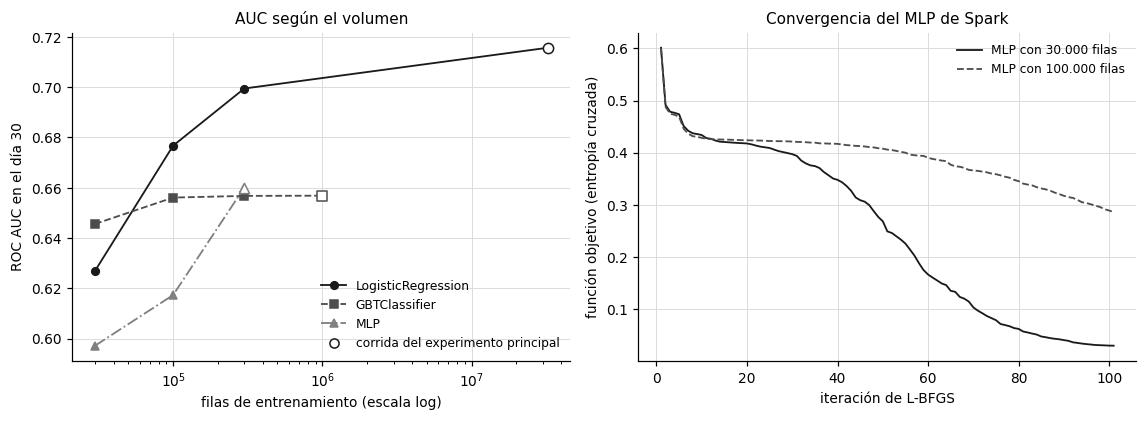

modelo,filas de entrenamiento,ROC AUC,log loss,ajuste (s),fuente
GBTClassifier,30.000,"0,6456","0,4396","5,6132",curva de aprendizaje
GBTClassifier,100.000,"0,6561","0,4381","4,3057",curva de aprendizaje
GBTClassifier,300.000,"0,6568","0,4377","6,9083",curva de aprendizaje
GBTClassifier,1.000.000,"0,6569","0,4374","273,7198",experimento principal
LogisticRegression,30.000,"0,6270","0,5024","5,2763",curva de aprendizaje
LogisticRegression,100.000,"0,6767","0,4330","6,3577",curva de aprendizaje
LogisticRegression,300.000,"0,6995","0,4194","3,6823",curva de aprendizaje
LogisticRegression,32.377.421,"0,7157","0,4131","502,8322",experimento principal
MLP,30.000,"0,5972","1,7397","132,6420",curva de aprendizaje
MLP,100.000,"0,6173","0,5738","471,1711",curva de aprendizaje


In [3]:
ca = pd.read_csv(ART / "spark" / "curva_aprendizaje.csv")
hist = json.loads((ART / "spark" / "mlp_historial_objetivo.json").read_text(encoding="utf-8"))
nombres_sp = {"lr": "LogisticRegression", "gbt": "GBTClassifier", "mlp": "MLP"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.9))
for a in (a1, a2):
    a.grid(True, color="#d9d9d9", linewidth=0.6); a.set_axisbelow(True)
    for s in ("top", "right"): a.spines[s].set_visible(False)
for (m, nom), st in zip(nombres_sp.items(), series_styles(3)):
    g = ca[ca["modelo"] == m].sort_values("filas_entrenamiento")
    a1.plot(g["filas_entrenamiento"], g["roc_auc"], label=nom, color=st["color"], linestyle=st["linestyle"],
            marker=st["marker"], markersize=5, linewidth=1.2)
    r = g[g["fuente"] == "experimento principal"]
    a1.scatter(r["filas_entrenamiento"], r["roc_auc"], marker=st["marker"], facecolor="white", edgecolor=st["color"], s=45, zorder=3)
a1.scatter([], [], marker="o", facecolor="white", edgecolor="#1a1a1a", label="corrida del experimento principal")
a1.set_xscale("log"); a1.set_xlabel("filas de entrenamiento (escala log)"); a1.set_ylabel("ROC AUC en el día 30")
a1.set_title("AUC según el volumen", fontsize=10); a1.legend(frameon=False, fontsize=8)
for (n, h), st in zip(sorted(hist.items(), key=lambda kv: int(kv[0])), series_styles(2)):
    a2.plot(range(1, len(h) + 1), h, label=f"MLP con {es(int(n))} filas", color=st["color"], linestyle=st["linestyle"], linewidth=1.2)
a2.set_xlabel("iteración de L-BFGS"); a2.set_ylabel("función objetivo (entropía cruzada)")
a2.set_title("Convergencia del MLP de Spark", fontsize=10); a2.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
t = ca.copy()
t["modelo"] = t["modelo"].map(nombres_sp)
tabla(t[["modelo", "filas_entrenamiento", "roc_auc", "log_loss", "tiempo_ajuste_s", "fuente"]].rename(columns={
    "filas_entrenamiento": "filas de entrenamiento", "roc_auc": "ROC AUC", "log_loss": "log loss", "tiempo_ajuste_s": "ajuste (s)"}),
      d=4, enteros=("filas de entrenamiento",))

**Interpretación.** Los tres modelos de Spark mejoran con el volumen, pero a ritmos muy distintos. La regresión logística pasa de un AUC de 0,6270 con 30.000 filas a 0,6767 con 100.000, 0,6995 con 300.000 y 0,7157 con el train completo, y su log loss baja de 0,5024 a 0,4131. El GBT se estanca casi de inmediato: 0,6456 con 30.000 filas, 0,6561 con 100.000 y 0,6568 y 0,6569 con 300.000 y con 1.000.000. El MLP es el que más depende del volumen, con 0,5972, 0,6173 y 0,6601 en los tres tamaños, y su log loss en prueba cae de 1,7397 a 0,4515. En el panel derecho, la función objetivo del MLP no se estabiliza: con los dos tamaños llega al tope de 100 iteraciones todavía bajando, y con 30.000 filas termina en 0,0300, mientras su log loss en prueba es de 1,7397.

Lo anterior indica que cada modelo de Spark tiene un límite distinto. El GBT llega a su techo con 100.000 filas porque solo ve las 5 variables de baja cardinalidad: con pocas combinaciones posibles, unas decenas de miles de filas bastan para estimar la tasa de clic de cada hoja, y su límite es la representación, no el volumen. La regresión logística sigue mejorando hasta el train completo, porque necesita muchas filas para estimar los pesos de las 4.101 columnas, entre ellas las de categorías poco frecuentes. El MLP muestra un sobreajuste fuerte: con 30.000 filas, su entropía cruzada de entrenamiento (0,0300) es 58 veces menor que la de prueba, y la brecha se reduce con 100.000 filas (0,2862 frente a 0,5738). Es lo esperable en una red sin regularización ni parada temprana (sección 5.5), que solo se controla con el volumen de datos, y su curva sigue subiendo en 300.000 filas, justo donde la densificación de la entrada obligó a cortar la muestra (sección 5.3). La comparación con scikit-learn (sección 4.4) aísla el efecto de la implementación: con unas 80.000 filas, el MLP de scikit-learn ya alcanza 0,7119, 0,0946 más que el de Spark con 100.000, así que la brecha entre entornos no se debe a la cantidad de datos, sino a la representación (target encoding y hashing de 2^12) y a la regularización.

Por tal motivo, se concluye que en Spark el uso más eficiente es la regresión logística con todo el train, y que el MLP de Spark necesitaría a la vez más datos y regularización, dos cosas que su implementación no permite en esta máquina. Hay que tener en cuenta que los tiempos de ajuste de esta tabla se midieron con la muestra en caché; los del experimento principal no son comparables, porque allí cada iteración volvía a leer el train completo para tomar la muestra.